# 15 - When the season turns: coverage under drift with ACI and conformal PID

> "The bands were perfect all winter. In July we caught them under-covering three weeks
> running. Do we recalibrate every week, or can the band correct itself?" - Kestrel
> facilities lead

Every band calibrated once eventually does what the facilities lead describes: it keeps the
promise of the world it was calibrated in. The sharper statistical question has three parts.
When the relationship between the features and the load moves, which band layer keeps its
90% promise: one calibrated once, one recalibrated on a trailing window, one that reweights
recent hours, or one that corrects itself after every hour? Over what horizon does each
promise hold: every week, or only on average over a long stream? And what does each pay for
it in width, interval score and outright infinite or empty bands? We answer on one stream with a
deliberate level shift, reporting long-run coverage and the worst week side by side, because
the complaint was not about the year. It was about three weeks.

**What you will learn**

- Why a band calibrated once fails silently after a level shift, and why the coverage of the
  whole stream can hide it: report weekly coverage, worst week first.
- Two recalibration fixes, a trailing window and the recency-weighted conformal method of
  Barber, Candes, Ramdas and Tibshirani (2023), and what that method's theorem does and does
  not promise.
- Adaptive conformal inference (ACI) and conformal PID, written from scratch to match the
  authors' update rules, with their long-run guarantees checked against executed numbers.
- How to run and read a drift bake-off: long-run, pre-shift, post-shift and worst-week
  coverage, width, interval score and infinite or empty bands, on a building meter and on a VM.
- What each guarantee actually says, in a table you can lift into a project report.

**Where we are in the series.** This is the last notebook of Part II. Notebook 14 turned band
edges into alarm limits and watched the forecaster chase the fault; notebook 09 gave you the
conformal test martingale that tells you *when* exchangeability broke, and promised that the
recency-weighted method would be implemented here. This notebook is about what the band
should do next. It leans on notebooks 05 and 12 (CQR scores), notebook 07 (the weighted
quantile with a phantom score at plus infinity, and concept drift), notebook 10 (misses
travel together), notebook 11 (walk-forward and the interval score), notebook 03 (the coverage
lottery, and why no method can promise per-hour coverage) and bonus 02 (EnbPI). After it,
`PROJECT_GUIDE.md` maps the project's objectives onto the seven Part II notebooks.

## 1. Drift, three ways

Notebook 09's zoo of violations put "time order with drift" first and pointed here for the
repair. In a forecasting project, **drift** (the relationship or the level changing over
time) arrives in three everyday shapes:

| Kind of drift | What changes | Kestrel example | Can notebook 07's reweighting repair it? | What the band layer must do |
|---|---|---|---|---|
| Season change | the mix of conditions, and usually the size of the errors that comes with them | the first heat wave after a mild spring | only if P(load given features) is unchanged and the likelihood ratio can be estimated; the error spread usually moves too | widen and narrow with the season without being told |
| Level shift | the relationship itself: the same hour, weather and recent load now mean more kWh | a new tenant moves in, a retrofit, a VM redeployed with a heavier release | no: this is concept drift (field guide §10), and old scores describe a building that no longer exists | notice the misses and correct within days, not months |
| Cold start | there is no history at all | a new building joins the portfolio, a new VM spins up | no: there are no calibration rows of its own to reweight | start wide and earn narrowness (section 7) |

Notebook 07's repair rested on one sentence you had to be able to write: only the mix of
inputs changed, the input-to-output rule did not. After a level shift that sentence is false,
and no reweighting of old scores by a likelihood ratio can say anything about the new rule.
What remains is to adapt online: let the hours that have just happened tell the band how
wrong it has been, and correct. This notebook stages the hardest of the three shapes for a
band, a sudden level shift, and compares four ways of doing that.

The code below copies the shared Part II functions verbatim: the two simulators,
`make_direct_table`, `MODEL_FEATURES`, `quantile_gbm` and the metrics. Read the docstring of
`simulate_building_load` once more. Its last bullet, the optional regime change, was written
for this notebook.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

In [2]:
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_vm_cpu(n_days, seed, start="2019-01-01", base_pct=22.0, daily_amp=8.0,
                    bursts_per_day=5.0, n_redeploys=2):
    """Simulate 5-minute average CPU utilisation (%) for one Kestrel virtual machine.

    What the simulator bakes in (and what later notebooks test against):
    - A weak daily rhythm (busier in business hours) on top of a level that jumps when the
      service is redeployed. The jumps are sudden and unannounced.
    - Bursts: spikes arriving at random times (batch jobs, traffic surges) that decay over
      a few readings. They make the series bursty - the reason simple baselines are so hard
      to beat on cloud data.
    - Readings are clipped to [0, 100]. During heavy bursts the VM saturates and reports
      exactly 100.0 several readings in a row - a legitimate flat line that a naive
      stuck-sensor rule will mistake for a frozen gateway (notebook 13).

    Returns a DataFrame indexed by 5-minute timestamp with column `cpu_pct`.
    """
    rng = np.random.default_rng(seed)
    steps_per_day = 288
    n = steps_per_day * n_days
    idx = pd.date_range(start, periods=n, freq="5min")
    hour = idx.hour.to_numpy() + idx.minute.to_numpy() / 60.0

    # Level that jumps at redeployments.
    level = np.full(n, base_pct)
    for when in np.sort(rng.integers(steps_per_day * 2, n, size=n_redeploys)):
        level[when:] = level[when:] * rng.lognormal(0.0, 0.35)

    daily = daily_amp * np.clip(np.sin(np.pi * (hour - 7) / 12), 0.0, None)

    # Bursts: random arrivals, random heights, exponential decay over a few readings.
    burst = np.zeros(n)
    n_bursts = rng.poisson(bursts_per_day * n_days)
    for start_step, height, decay in zip(rng.integers(0, n, size=n_bursts),
                                         rng.exponential(35.0, size=n_bursts),
                                         rng.uniform(2.0, 10.0, size=n_bursts)):
        span = np.arange(start_step, min(start_step + int(6 * decay), n))
        burst[span] += height * np.exp(-(span - start_step) / decay)

    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.6 * ar[i - 1] + z[i]
    cpu = level + daily + burst + 2.5 * ar
    return pd.DataFrame({"cpu_pct": np.clip(cpu, 0.0, 100.0)}, index=idx)


# ------------------------------------------------- THE FORECASTING TABLE

def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()


MODEL_FEATURES = ["last_value", "mean_last_day", "same_time_yesterday", "same_time_last_week",
                  "median_14d_same_time", "target_hour", "target_dow"]


def quantile_gbm(q, seed=20260707):
    """Gradient-boosted quantile model used by every Part II notebook.

    Small and fast on purpose (each fit takes well under a second). early_stopping=False
    matters: scikit-learn's automatic early stopping holds out a RANDOM 10% of rows, which
    on time-ordered data quietly lets the model peek at its own future.
    """
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=60,
                                         learning_rate=0.15, max_leaf_nodes=15,
                                         early_stopping=False, random_state=seed)


def interval_score(y, lo, hi, alpha):
    """Gneiting-Raftery interval score of a central (1 - alpha) band; lower is better.

    Width, plus a penalty of 2/alpha per unit of distance for every observation that lands
    outside the band. A band that is too narrow pays in misses; a band that is too wide
    pays in width. Averaged over observations.
    """
    y, lo, hi = np.asarray(y), np.asarray(lo), np.asarray(hi)
    return float(np.mean((hi - lo)
                         + (2.0 / alpha) * np.maximum(lo - y, 0.0)
                         + (2.0 / alpha) * np.maximum(y - hi, 0.0)))


def band_report(y, point, lo, hi, alpha):
    """MAE of the point forecast, plus coverage, mean width and interval score of the band."""
    y, point, lo, hi = map(np.asarray, (y, point, lo, hi))
    return {
        "MAE": float(np.mean(np.abs(y - point))),
        "coverage": float(np.mean((y >= lo) & (y <= hi))),
        "width": float(np.mean(hi - lo)),
        "interval_score": interval_score(y, lo, hi, alpha),
    }


def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])

The stream we build is the simplest one that contains the facilities lead's problem:

- `simulate_building_load(730, seed=RANDOM_SEED, shift_day=560, shift_frac=0.25)`: two years
  of hourly readings, 2016-2017, and from day 560 (14 July 2017) on every reading is 25%
  higher. A new tenant moved in; nobody told the forecasting team.
- Horizon `h = 1` (next hour), so every hit or miss is known before the next forecast is
  issued. Section 7 deals with longer horizons.
- Three quantile models (`ALPHA / 2`, `0.5`, `1 - ALPHA / 2`) from `quantile_gbm`, fitted ONCE on
  every target before day 301 (about ten months, to late October 2016) with
  `MODEL_FEATURES + ["exog_at_target"]`. Temperature at the target hour is treated as a known
  weather forecast, as in notebooks 11 and 12.
- Calibration: the next 30 days of CQR scores `s_t = max(lo_t - y_t, y_t - hi_t)`, notebook
  05's score: negative when the reading sits inside the raw quantile band, positive by the
  distance it lands outside.
- The stream: the remaining 399 days, exactly 57 weeks or 9,576 hours, scored one hour at a
  time by every method in this notebook.

Freezing the model is a deliberate choice. It isolates what the band layer can do on its own.
In production you would also refit on a walk-forward schedule (notebook 11, field guide §15),
and a refit shortens the damage; but between refits the band is on its own, and that gap is
what this notebook studies.

In [3]:
SHIFT_DAY = 560        # 14 July 2017: a new tenant moves in, every reading +25% from here on
TRAIN_END_DAY = 301    # the model sees targets before this day, and is never refitted
CAL_DAYS = 30          # the next 30 days of scores calibrate the band
WEEK = 24 * 7

b = simulate_building_load(730, seed=RANDOM_SEED, shift_day=SHIFT_DAY, shift_frac=0.25)
tab = make_direct_table(b["load_kwh"], h=1, period=24, exog=b["temp_c"])
features = MODEL_FEATURES + ["exog_at_target"]   # temperature as a known weather forecast

# Position of every target in hours since 2016-01-01 00:00, and in whole days.
target_hour = ((tab["target_time"] - b.index[0]) / pd.Timedelta(hours=1)).to_numpy().astype(int)
target_day = target_hour // 24
is_train = target_day < TRAIN_END_DAY
is_cal = (target_day >= TRAIN_END_DAY) & (target_day < TRAIN_END_DAY + CAL_DAYS)
is_stream = target_day >= TRAIN_END_DAY + CAL_DAYS

X, y_all = tab[features].to_numpy(), tab["target"].to_numpy()
quantile_models = {q: quantile_gbm(q).fit(X[is_train], y_all[is_train])
                   for q in (ALPHA / 2, 0.5, 1 - ALPHA / 2)}

# From here on: calibration + stream rows only, in time order. Every method below sees
# the same score sequence; position START is the first streamed hour.
keep = is_cal | is_stream
raw_lo = quantile_models[ALPHA / 2].predict(X[keep])
point = quantile_models[0.5].predict(X[keep])
raw_hi = quantile_models[1 - ALPHA / 2].predict(X[keep])
y = y_all[keep]
hours = target_hour[keep]
times = pd.DatetimeIndex(tab["target_time"].to_numpy()[keep])
scores = np.maximum(raw_lo - y, y - raw_hi)   # CQR score: > 0 means the raw band missed
START = int(is_cal.sum())
post = hours[START:] >= 24 * SHIFT_DAY        # streamed hours after the tenant arrived

assert np.all(np.diff(hours) == 1), "calibration and stream must be consecutive hours"
assert (len(scores) - START) % WEEK == 0, "the stream should be a whole number of weeks"

n_stream = len(scores) - START
print(f"training rows:     {is_train.sum():>5}  (targets {tab['target_time'][is_train].min():%Y-%m-%d} "
      f"to {tab['target_time'][is_train].max():%Y-%m-%d}), fitted once")
print(f"calibration hours: {START:>5}  ({times[0]:%Y-%m-%d} to {times[START - 1]:%Y-%m-%d})")
print(f"streamed hours:    {n_stream:>5}  = {n_stream // WEEK} weeks ({times[START]:%Y-%m-%d} to "
      f"{times[-1]:%Y-%m-%d}): {np.sum(~post)} before the shift, {np.sum(post)} after")
print(f"calibration scores: min {scores[:START].min():.1f}, median {np.median(scores[:START]):.1f}, "
      f"max {scores[:START].max():.1f} kWh (range {np.ptp(scores[:START]):.1f})")
print(f"raw quantile band coverage: calibration {np.mean(scores[:START] <= 0):.3f}, "
      f"stream before shift {np.mean(scores[START:][~post] <= 0):.3f}, "
      f"after {np.mean(scores[START:][post] <= 0):.3f}")

training rows:      6888  (targets 2016-01-15 to 2016-10-27), fitted once
calibration hours:   720  (2016-10-28 to 2016-11-26)
streamed hours:     9576  = 57 weeks (2016-11-27 to 2017-12-30): 5496 before the shift, 4080 after
calibration scores: min -60.2, median -5.9, max 51.7 kWh (range 111.9)
raw quantile band coverage: calibration 0.829, stream before shift 0.855, after 0.686


Read the printout as the design of an experiment. The model learned from 6,888 hourly
targets, January to late October 2016, and is never refitted. The calibration window is the
720 hours from 28 October to 26 November 2016, and the stream runs from 27 November 2016 to
30 December 2017: 57 weeks, of which 5,496 hours come before the new tenant and 4,080 after.

The calibration scores run from -60.2 to 51.7 kWh around a median of -5.9: most readings sit
inside the raw quantile band (negative scores), a few land well outside. The raw band itself,
the unconformalized 5%-95% quantile models, covers only 0.829 of the calibration hours, the
under-coverage notebook 12 measured and the reason the conformal step exists. Before the shift
it covers 0.855 of the streamed hours, after the shift 0.686. Nothing about the band's
promise has been computed yet; these numbers only say that the raw quantile models were never
calibrated, and that they get worse when the building changes under them.

daily mean score before the shift: -17.8 to 1.0 kWh, above -3 on 15 of 259 days
on the day of the shift: 33.4 kWh; the next four days: 2.6 0.7 -5.8 13.3
largest daily mean later that summer: 20.4 kWh on 31 July; in November-December: 38.2 kWh on 21 November


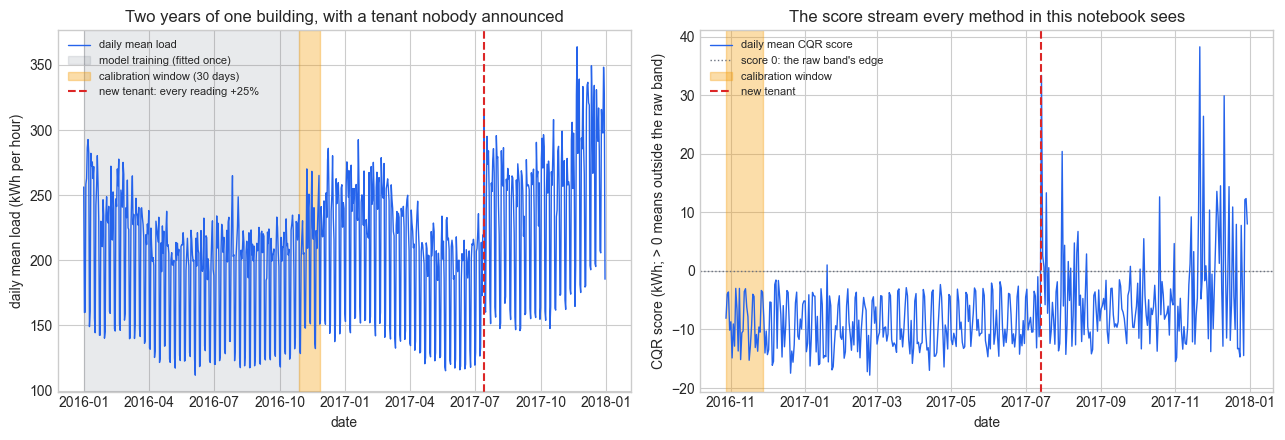

In [4]:
daily_load = b["load_kwh"].resample("D").mean()
daily_score = pd.Series(scores, index=times).resample("D").mean()
shift_time = b.index[24 * SHIFT_DAY]
pre_days = daily_score[:shift_time - pd.Timedelta(days=1)]
post_days = daily_score[shift_time:]
summer, winter = post_days[:"2017-08-31"].iloc[1:], post_days["2017-11-01":]
print(f"daily mean score before the shift: {pre_days.min():.1f} to {pre_days.max():.1f} kWh, "
      f"above -3 on {np.sum(pre_days > -3)} of {len(pre_days)} days")
print(f"on the day of the shift: {post_days.iloc[0]:.1f} kWh; the next four days: "
      f"{' '.join(f'{v:.1f}' for v in post_days.iloc[1:5])}")
print(f"largest daily mean later that summer: {summer.max():.1f} kWh on {summer.idxmax():%d %B}; "
      f"in November-December: {winter.max():.1f} kWh on {winter.idxmax():%d %B}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(daily_load.index, daily_load.to_numpy(), color=BLUE, lw=1, label="daily mean load")
ax.axvspan(b.index[0], times[0], color=GRAY, alpha=0.15, label="model training (fitted once)")
ax.axvspan(times[0], times[START], color=AMBER, alpha=0.35, label="calibration window (30 days)")
ax.axvline(shift_time, color=RED, ls="--", lw=1.5, label="new tenant: every reading +25%")
ax.set_title("Two years of one building, with a tenant nobody announced")
ax.set_xlabel("date")
ax.set_ylabel("daily mean load (kWh per hour)")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
ax.plot(daily_score.index, daily_score.to_numpy(), color=BLUE, lw=1, label="daily mean CQR score")
ax.axhline(0, color=GRAY, ls=":", lw=1, label="score 0: the raw band's edge")
ax.axvspan(times[0], times[START], color=AMBER, alpha=0.35, label="calibration window")
ax.axvline(shift_time, color=RED, ls="--", lw=1.5, label="new tenant")
ax.set_title("The score stream every method in this notebook sees")
ax.set_xlabel("date")
ax.set_ylabel("CQR score (kWh; > 0 means outside the raw band)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

The left panel is the building as the meter saw it: two summers and two winters of heating and
cooling, then on 14 July 2017 a step up of a quarter that never goes away. The model was
fitted on the gray stretch and calibrated on the amber one; it has never seen a summer
afternoon at the new tenant's level.

The right panel is what matters for the rest of the notebook: the daily mean CQR score. Before
the shift it runs between -17.8 and +1.0 kWh, swinging with the weekday-weekend rhythm, and
rises above -3 on only 15 of the 259 days. On 14 July it jumps the same day, to 33.4 kWh, then
swings around zero (2.6, 0.7, -5.8 and 13.3 over the next four days), with another spike to
20.4 kWh on 31 July. In November and December 2017 it spikes again, to 38.2 kWh on
21 November, when winter heating at 125% pushes the load beyond anything the frozen model was
trained on. Every band layer below
sees exactly this sequence, hour by hour, and none of them can change the model's point
forecast. They can only decide how much to add to the raw band.

## 2. Split CQR, calibrated once

The recipe is notebook 05's CQR, wrapped as notebook 12 did: take the corrected quantile
`q_hat` of the 720 calibration scores (`corrected_quantile`, notebook 02's rule: the 649th
smallest, because (720 + 1) x 0.90 = 648.9 rounds up to 649) and quote the
band `[lo - q_hat, hi + q_hat]` for every streamed hour. Under exchangeability of the
calibration hours and the streamed hours this carries the finite-sample 90% guarantee. The
stream is not exchangeable with the calibration window, and we are about to measure what that
costs.

Every method in this notebook produces the same object, one band offset `q[t]` per hour, so
one helper scores them all. `stream_report` returns long-run coverage over the 57 weeks,
coverage before and after the shift, the **worst week** (the lowest coverage of any of the 57
seven-day blocks), the number of weeks below 0.85, the mean width and interval score (field
guide §18), and the counts of infinite and empty bands. An **empty band** is one whose lower
edge sits above its upper edge, which happens when the offset is more negative than minus half
the raw band's width. It contains no value at all, so it always misses. Like an infinite band,
it is kept out of the width and interval-score averages: its hi - lo would enter the width
average as a negative number, and the interval score is defined only for a lower edge at or
below the upper one. Section 6 checks that this convention does not decide the ranking. The
0.85 line is a "someone will ask" threshold, not a test: with 168 hours a week and misses that travel together (notebook 10), a healthy 90%
band still drifts into the mid-80s now and then.

q_hat from 720 calibration scores: 2.63 kWh added to each side of the raw band
before the shift: coverage 0.915, width 48.0 kWh, MAE of the median 10.33, interval score 62.1
after the shift:  coverage 0.745, width 64.6 kWh, MAE of the median 23.34, interval score 169.6
whole stream: coverage 0.843; worst week 0.548 (week of 2017-11-19); 21 of 57 weeks below 0.85
weekly coverage, the week containing the shift and the five after it: [0.756 0.72  0.863 0.762 0.768 0.768]
weeks below 0.85 before the week of the shift: 1 (lowest 0.833, week of 2017-02-26)


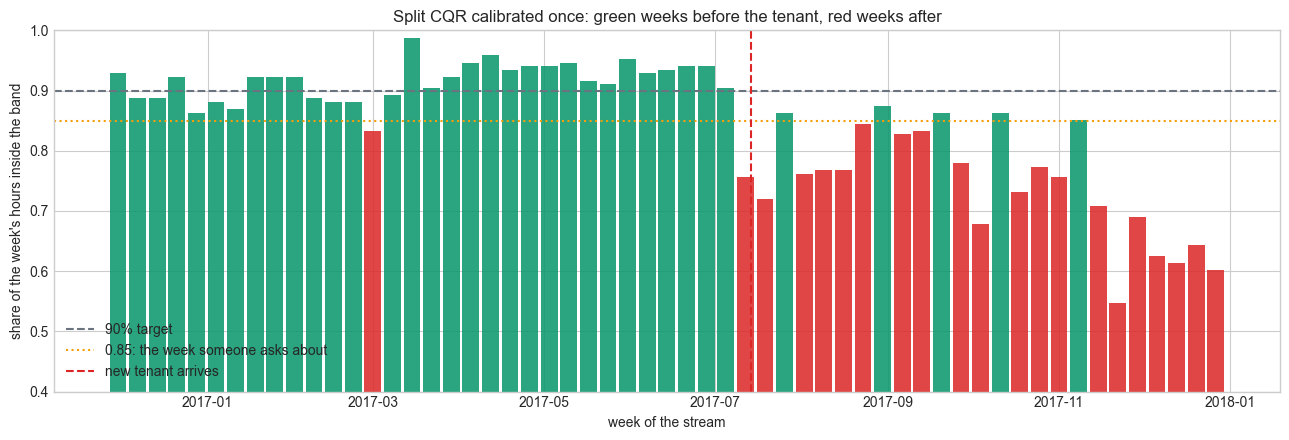

In [5]:
def block_coverage(q, scores, start, block):
    """Coverage of each consecutive block of `block` streamed rows (168 hours = one week)."""
    covered = scores[start:] <= q[start:]
    n_blocks = len(covered) // block
    return covered[: n_blocks * block].reshape(n_blocks, block).mean(axis=1)


def stream_report(q, scores, raw_lo, raw_hi, y, start, is_post, block, block_name="week"):
    """Score a sequence of band offsets on the streamed rows (positions start, start + 1, ...).

    The band for row t is [raw_lo[t] - q[t], raw_hi[t] + q[t]]: CQR's raw quantile band,
    widened by the offset. An offset of +inf is an infinite band (it always covers). An
    offset of -inf, or a finite offset so negative that the lower edge lands above the upper
    edge, is an empty band: it contains no value at all and always misses. Width and interval
    score are averaged over the finite, non-empty bands only. An infinite band has infinite
    width; an empty band has no width at all (its hi - lo would enter the width average as a
    negative number), and the interval score is defined only for a lower edge at or below the
    upper one. So always read them next to the counts of infinite and empty bands (field
    guide S22).
    """
    qs, covered = q[start:], scores[start:] <= q[start:]
    per_block = block_coverage(q, scores, start, block)
    lo_all, hi_all = raw_lo[start:] - qs, raw_hi[start:] + qs
    empty = lo_all > hi_all                          # q = -inf included: +inf > -inf
    assert not np.any(covered & empty), "an empty band can never cover"
    kept = np.isfinite(qs) & ~empty                  # finite, non-empty bands
    lo_band, hi_band = lo_all[kept], hi_all[kept]
    return {
        "long_run": covered.mean(),
        "pre_shift": covered[~is_post].mean(),
        "post_shift": covered[is_post].mean(),
        f"worst_{block_name}": per_block.min(),
        f"{block_name}s_below_0.85": int((per_block < 0.85).sum()),
        "mean_width": float(np.mean(hi_band - lo_band)),
        "interval_score": interval_score(y[start:][kept], lo_band, hi_band, ALPHA),
        "infinite_bands": int(np.sum(qs == np.inf)),
        "empty_bands": int(np.sum(empty)),
    }


def building_report(q):
    """stream_report on the building stream of this notebook, one row per method."""
    return stream_report(q, scores, raw_lo, raw_hi, y, START, post, WEEK)


def report_table(rows):
    """One row per method (rows: name -> report dict); count columns stay integers."""
    table = pd.DataFrame(rows).T
    counts = [c for c in table.columns if "below" in c or "infinite" in c or "empty" in c]
    return table.astype({c: int for c in counts})


offsets = {}   # method name -> one band offset per row of `scores`; the bake-off reads this
q_hat = corrected_quantile(scores[:START], ALPHA)
offsets["split CQR, calibrated once"] = np.full(len(scores), q_hat)

rep = building_report(offsets["split CQR, calibrated once"])
before = band_report(y[START:][~post], point[START:][~post], raw_lo[START:][~post] - q_hat,
                     raw_hi[START:][~post] + q_hat, ALPHA)
after = band_report(y[START:][post], point[START:][post], raw_lo[START:][post] - q_hat,
                    raw_hi[START:][post] + q_hat, ALPHA)
weekly_split = block_coverage(offsets["split CQR, calibrated once"], scores, START, WEEK)
week_start = times[START::WEEK][: len(weekly_split)]

print(f"q_hat from 720 calibration scores: {q_hat:.2f} kWh added to each side of the raw band")
print(f"before the shift: coverage {before['coverage']:.3f}, width {before['width']:.1f} kWh, "
      f"MAE of the median {before['MAE']:.2f}, interval score {before['interval_score']:.1f}")
print(f"after the shift:  coverage {after['coverage']:.3f}, width {after['width']:.1f} kWh, "
      f"MAE of the median {after['MAE']:.2f}, interval score {after['interval_score']:.1f}")
print(f"whole stream: coverage {rep['long_run']:.3f}; worst week {rep['worst_week']:.3f} "
      f"(week of {week_start[np.argmin(weekly_split)]:%Y-%m-%d}); "
      f"{rep['weeks_below_0.85']} of {len(weekly_split)} weeks below 0.85")
first_post_week = int(np.argmax(week_start >= shift_time - pd.Timedelta(days=6)))
print("weekly coverage, the week containing the shift and the five after it:",
      np.round(weekly_split[first_post_week:first_post_week + 6], 3))
before_shift = weekly_split[:first_post_week]
print(f"weeks below 0.85 before the week of the shift: {np.sum(before_shift < 0.85)} "
      f"(lowest {before_shift.min():.3f}, week of {week_start[np.argmin(before_shift)]:%Y-%m-%d})")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(week_start, weekly_split, width=6, align="edge",
       color=np.where(weekly_split < 0.85, RED, GREEN), alpha=0.85)
ax.axhline(1 - ALPHA, color=GRAY, ls="--", lw=1.5, label="90% target")
ax.axhline(0.85, color=AMBER, ls=":", lw=1.5, label="0.85: the week someone asks about")
ax.axvline(shift_time, color=RED, ls="--", lw=1.5, label="new tenant arrives")
ax.set_ylim(0.4, 1.0)
ax.set_title("Split CQR calibrated once: green weeks before the tenant, red weeks after")
ax.set_xlabel("week of the stream")
ax.set_ylabel("share of the week's hours inside the band")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

The stale band keeps its promise exactly as long as the world it was calibrated in lasts. With
`q_hat` = 2.63 kWh added to each side, it covers 0.915 of the hours before the shift: the
facilities lead's "perfect all winter", and a little above target, because the November
calibration window happened to be a harder month than the winter and spring that followed.
After the tenant arrives the same band covers 0.745. The weekly bars tell the story the lead
told: the week containing the shift drops to 0.756, the next to 0.720, and every one of the
six weeks printed stays below 90%. Only one red week (0.833, the week of 26 February) comes
before the shift; after it, red weeks outnumber green ones. The worst week is 0.548, the week of
19 November 2017, and 21 of the 57 weeks sit below 0.85.

Three things to notice. First, coverage over the whole stream is 0.843: bad, but it averages
229 healthy days with 170 broken ones and would look merely disappointing in a summary table.
That is why every table in this notebook carries a worst-week column. Second, the point forecast
broke too: the MAE of the median model more than doubles, from 10.33 to 23.34 kWh, and the
interval score of the band rises from 62.1 to 169.6 even though its average width grew from
48.0 to 64.6 kWh with the raw quantile models. No band layer can repair the point forecast;
only a refit can. Third, nothing raised an error. `q_hat` is still a
perfectly valid quantile of 720 scores from a building that no longer exists (field guide §6
and §10).

What 0.745 does not mean: it does not mean conformal prediction failed. It means its one
assumption, that the streamed hours could be shuffled in with the calibration hours, was
broken on 14 July: the kind of break notebook 09's conformal test martingale exists to flag,
and the moment to stop quoting the split-conformal guarantee (field guide §14).

## 3. The obvious fix: recalibrate on recent data

The facilities lead's instinct is the right first instinct: if a band calibrated on the past
goes stale, calibrate it on the recent past. Every midnight we recompute the corrected
quantile over the trailing 30 days of scores (720 hours) and use it for the next 24 hours.
Nothing else changes. Two predictions before we run it. It must recover, because 30 days after
the shift the window contains only the new tenant. And it must lag, because for the first
days after the shift the window is mostly the old building. It looks like a heuristic, but it
is not one: a trailing window is a fixed, age-based weighting of the past scores, and the
theorem we meet in a moment covers it.

In [6]:
WINDOW = 720   # 30 days of hourly scores, the same length as the original calibration window

q_roll = np.full(len(scores), np.nan)
for t in range(START, len(scores), 24):           # every midnight...
    # ...the 720 scores whose targets are already observed (h = 1: everything up to t - 1).
    q_roll[t:t + 24] = corrected_quantile(scores[t - WINDOW:t], ALPHA)
offsets["rolling 30-day window"] = q_roll

weekly_roll = block_coverage(q_roll, scores, START, WEEK)
rep_roll = building_report(q_roll)
print(f"rolling 30-day window: long-run {rep_roll['long_run']:.3f}, before shift "
      f"{rep_roll['pre_shift']:.3f}, after {rep_roll['post_shift']:.3f}, worst week "
      f"{rep_roll['worst_week']:.3f}, mean width {rep_roll['mean_width']:.1f} kWh")
around = slice(first_post_week - 1, first_post_week + 7)
pd.DataFrame({
    "week_starting": week_start[around].strftime("%Y-%m-%d"),
    "split_CQR": weekly_split[around],
    "rolling_30_day": weekly_roll[around],
    "rolling_offset_kWh": q_roll[START:][::WEEK][around],
}).round(3)

rolling 30-day window: long-run 0.891, before shift 0.902, after 0.876, worst week 0.702, mean width 65.5 kWh


,week_starting,split_CQR,rolling_30_day,rolling_offset_kWh
0,2017-07-02,0.905,0.869,0.883
1,2017-07-09,0.756,0.732,1.018
2,2017-07-16,0.720,0.774,3.837
3,2017-07-23,0.863,0.911,8.091
4,2017-07-30,0.762,0.863,9.711
5,2017-08-06,0.768,0.911,12.620
6,2017-08-13,0.768,0.887,15.519
7,2017-08-20,0.845,0.940,11.787


The rolling window does both things we predicted. Over the stream it covers 0.891 (0.902 before
the shift, 0.876 after), against 0.843 for the stale band, and its worst week improves from
0.548 to 0.702. The table shows the mechanism. In the week of the shift it does no better than
the stale band (0.732 against 0.756): on the first day after the tenant arrives, the window
holds 29 days of the old building and one of the new, and its offset is about 1 kWh. Then the
offset climbs week by week, to 3.8, 8.1, 9.7, 12.6 and 15.5 kWh, as new-tenant scores replace
old ones; from the second week after the shift the rolling band is back above 0.85 in every
week shown, while the stale band stays mostly below it. The price is width: 65.5 kWh on
average against 55.1.

What the table does not show is how much coverage the window can lose. The rolling window
recovered because this shift was a single step that then stayed put. A building that drifts
slowly, or a VM that redeploys every few days, can keep a 30-day window permanently out of
date, and the bound below says how that is charged without letting you compute the charge.

### Recency-weighted calibration: the theorem behind every window

The trailing window is already a weighting, and a fixed one: weight 1 for a score at most 30
days old, weight 0 before. Fixed, age-based weights are exactly the setting of
**recency-weighted conformal** (Barber, Candes, Ramdas and Tibshirani 2023, "Conformal
prediction beyond exchangeability"), the method notebook 09 promised would be implemented
here. It is the same weighted-quantile construction as notebook 07, with weights chosen by age
instead of by a likelihood ratio: every past score gets a weight fixed in advance, the hour
being forecast gets weight 1 on a phantom score at plus infinity, and the band uses the
weighted corrected quantile. The trailing window is its 0/1 special case; the smooth version
we try here is `w_i = rho ** (age in days)`. With `rho = 0.9`, yesterday counts 0.9, last week
0.48 and a month ago 0.04; with `rho = 0.97`, 0.97, 0.81 and 0.40.

What do fixed weights buy? Their theorem, in words: coverage can fall below 90% by at most a
weighted average, over the past hours, of how much the distribution of the data would change
if you swapped that past hour with the hour being forecast. Past hours that resemble today
cost nothing; hours from a different regime cost up to their share of the weight. The hours
from before the shift are the expensive ones, and decaying weights make them cheap. In
symbols, with normalized weights $\tilde w_i = w_i / (w_1 + \dots + w_n + 1)$,

$$\Pr\{y_{n+1} \in \hat C(x_{n+1})\} \;\ge\; 1 - \alpha - \sum_{i=1}^{n} \tilde w_i \, d_{\mathrm{TV}}\big(R(Z),\, R(Z^{i})\big),$$

where $n$ is the number of past scores, $Z$ is the whole sequence of past points and the test
point, $Z^{i}$ is the same sequence with the test point and the $i$-th point swapped, $R(\cdot)$
is the vector of their scores under our fixed model, and $d_{\mathrm{TV}}$ is the total-variation
distance: the largest difference in probability that the two distributions assign to any event,
0 for identical distributions and 1 for completely different ones.

Two properties hold for any fixed weights, the trailing window's 0/1 weights included. If the
data happen to be exchangeable, every distance is zero and the full 90% guarantee returns:
fixed weights never hurt an exchangeable stream. And the weights must be fixed before the
scores are seen; age qualifies, a weight tuned on recent misses would not. So what separates
exponential weights from the trailing window is not that one has a theorem and the other does
not. It is how the weight fades: all at once on day 31, or a little every day. One caution: the distances are
unknown in practice, so the bound tells you what kind of data the method tolerates (data whose
recent past looks like its present), not a number you can compute. One more subtlety, from
notebook 07: weights shrink the calibration set, so we print the effective sample size
(field guide §11) next to every result.

In [7]:
# Copied verbatim from notebook 07, docstring included: there the test point was a home,
# here it is the hour being forecast.
def weighted_conformal_qhat(scores, w_scores, w_test, alpha):
    """Weighted corrected quantile (Tibshirani et al., 2019).

    Each calibration score votes with weight w_scores[i]; one phantom score at
    +infinity votes with the test home's own weight w_test - the reserved seat
    for the score we cannot observe. Returns the smallest score where the
    cumulative vote share reaches 1 - alpha, or +inf if the calibration set
    never accumulates that much weight (the honest 'I cannot certify this').
    """
    order = np.argsort(scores)
    cum_w = np.cumsum(w_scores[order])
    threshold = (1 - alpha) * (cum_w[-1] + w_test)
    idx = np.searchsorted(cum_w, threshold)
    if idx >= len(scores):
        return np.inf
    return scores[order][idx]


# The trailing window is the 0/1 special case: weight 1 on the last 720 scores, 0 before.
window0 = scores[START - WINDOW:START]
q01 = weighted_conformal_qhat(window0, np.ones(WINDOW), 1.0, ALPHA)
assert q01 == corrected_quantile(window0, ALPHA), "equal weights must reproduce the corrected quantile"
print(f"0/1 weights on the first 720-score window: {q01:.2f} kWh, the {np.sum(window0 <= q01)}th smallest; "
      f"corrected_quantile: {corrected_quantile(window0, ALPHA):.2f} kWh, the "
      f"{np.sum(window0 <= corrected_quantile(window0, ALPHA))}th")

score_day = hours // 24
for rho in (0.9, 0.97):
    q_w = np.full(len(scores), np.nan)
    n_eff = []
    for t in range(START, len(scores), 24):          # every midnight, like the rolling window
        age_days = score_day[t] - score_day[:t]       # 1 = yesterday, 2 = the day before, ...
        w = rho ** age_days                           # fixed in advance: depends on age only
        q_w[t:t + 24] = weighted_conformal_qhat(scores[:t], w, 1.0, ALPHA)
        n_eff.append(w.sum() ** 2 / np.sum(w ** 2))
    offsets[f"recency-weighted, rho {rho}"] = q_w
    print(f"rho = {rho}: effective sample size {np.mean(n_eff):.0f} hours "
          f"(about {np.mean(n_eff) / 24:.0f} days of equally weighted scores)")

report_table({name: building_report(q) for name, q in offsets.items()}).round(3)

0/1 weights on the first 720-score window: 2.63 kWh, the 649th smallest; corrected_quantile: 2.63 kWh, the 649th


rho = 0.9: effective sample size 455 hours (about 19 days of equally weighted scores)


rho = 0.97: effective sample size 1487 hours (about 62 days of equally weighted scores)


,long_run,pre_shift,post_shift,worst_week,weeks_below_0.85,mean_width,interval_score,infinite_bands,empty_bands
"split CQR, calibrated once",0.843,0.915,0.745,0.548,21,55.071,107.910,0,0
rolling 30-day window,0.891,0.902,0.876,0.702,6,65.472,98.896,0,0
"recency-weighted, rho 0.9",0.897,0.904,0.887,0.768,4,67.378,98.721,0,0
"recency-weighted, rho 0.97",0.887,0.906,0.861,0.702,7,63.346,99.208,0,0


The first printed line checks the special case. With weight 1 on each of the 720 scores of
the first window, the weighted quantile is 2.63 kWh, the 649th smallest score, and
`corrected_quantile` returns the same score, as the equality assertion requires. The phantom
score at plus infinity is notebook 02's n + 1 in another form: with equal weights it asks for a
cumulative weight of 0.90 x 721 = 648.9 out of 720, which the 649th score is the first to reach.
So the rolling window of the previous cell is covered by exactly the same bound.

Recency weighting with `rho = 0.9` is the best of the recalibration family on this stream: 0.897
long-run, 0.887 after the shift, a worst week of 0.768 against 0.702 for the trailing window,
at a mean width of 67.4 kWh and the lowest interval score of the four rows (98.7). Its 455-hour
effective sample size means it behaves like a 19-day window with soft edges, which forgets the
old building faster than the 30-day window does. With `rho = 0.97` the effective sample size
grows to 1,487 hours (about 62 days), the band remembers the old building for longer, and it
does slightly worse than the trailing window after the shift (0.861 against 0.876).

That ordering is consistent with what the theorem charges for: coverage is lost in proportion
to the weight placed on hours unlike today, the old building's hours in particular. Smaller `rho` puts less weight on the old building and pays less; it also
shrinks the effective sample, which brings back the coverage lottery of field guide §4. There
is no free `rho`, and choosing it on the stream you report would be tuning on the test set.

What these rows do not show: any method that reacts within the week of the shift. All four
recalibration rows update once a day from the distribution of recent scores, and for the first
days after a step change the recent scores are still mostly the old building. The next two
methods react to something faster: the misses themselves.

## 4. ACI: a thermostat for alpha

Recalibration asks what the recent scores looked like. **Adaptive conformal inference (ACI)**
(Gibbs and Candes 2021) asks a blunter question: did the last band miss? It keeps a working
miss budget `alpha_t` and treats it like a thermostat setting. After a miss it lowers
`alpha_t`, so the band asks for a higher quantile and widens; after a hit it raises `alpha_t` a
little, and the band narrows. The steps are sized so that when misses arrive at exactly 10%
the setting stays put: a miss costs 0.9 `gamma`, a hit gives back 0.1 `gamma`, and nine hits pay
for one miss. In symbols, with $\mathrm{err}_t = 1$ if hour $t$'s band missed and 0 otherwise,
$\gamma$ the step size and $\alpha = 0.10$ the target,

$$\alpha_{t+1} = \alpha_t + \gamma\,(\alpha - \mathrm{err}_t).$$

The band for hour $t$ is the corrected quantile, at level $1 - \alpha_t$, of the trailing 720
scores: the $k$-th smallest, with $k = \lceil (n+1)(1-\alpha_t) \rceil$ and $n = 720$. Two edge
cases are part of the method, not bugs. When $\alpha_t$ falls so low that no finite score
qualifies ($k$ exceeds $n$, which includes every $\alpha_t \le 0$), the band is infinite. When $\alpha_t$ reaches 1, the band
is empty.

**Why it works, in three lines.** Add up all the updates and the sum telescopes: the final
setting minus the first equals $\gamma$ times ($T\alpha$ minus the number of misses). The setting
can never leave $[-\gamma, 1 + \gamma]$: below zero the band is infinite and nothing can miss,
so it must rise; above one the band is empty and everything misses, so it must fall. So the
excess number of misses is bounded by a constant over $\gamma$, and the long-run miss rate
converges to $\alpha$:

$$\left|\frac{1}{T}\sum_{t=1}^{T}\mathrm{err}_t - \alpha\right| \;\le\; \frac{\max(\alpha_1,\, 1-\alpha_1) + \gamma}{\gamma\, T},$$

where $T$ is the number of streamed hours and $\alpha_1$ the starting setting (we start at 0.10).
Read the fine print twice. The bound is deterministic: no probability, no model, no assumption
about the data; it holds for ANY sequence of scores, an adversarial one included. And it is
long-run only: it says nothing about a given week, and a week is a small $T$. The step size
$\gamma$ trades the two: a large $\gamma$ tightens the long-run bound and reacts fast, and it
also swings $\alpha_t$ below zero, which is where infinite bands come from (field guide §22).
Aggregated ACI, AgACI (Zaffran and colleagues 2022), runs several values of $\gamma$ side by side
and combines their bands with online expert aggregation, which spares you the choice; we stay
with a sweep so that you can see what the choice does.

In [8]:
def aci_offset(window_scores, alpha_t):
    """Band offset at working level alpha_t: the corrected quantile at level 1 - alpha_t.

    The two edge cases are what keep alpha_t inside [-gamma, 1 + gamma], which the long-run
    bound needs - do not 'fix' them:
    - alpha_t >= 1 asks for a 0% band: return -inf, an empty band that always misses.
    - alpha_t so small that ceil((n + 1)(1 - alpha_t)) > n (every alpha_t <= 0 included):
      no finite score qualifies, so the band is infinite and always covers.
    """
    n = len(window_scores)
    if alpha_t >= 1:
        return -np.inf
    k = math.ceil((n + 1) * (1 - alpha_t))
    if k > n:
        return np.inf
    return float(np.sort(window_scores)[k - 1])          # the k-th smallest of the n scores


def run_aci(scores, start, alpha, gamma, window):
    """Adaptive conformal inference (Gibbs and Candes 2021), one row at a time.

    Before row t: offset = aci_offset of the trailing `window` scores at level alpha_t.
    After row t: the miss err_t is observed (h = 1) and
    alpha_{t+1} = alpha_t + gamma * (alpha - err_t). Returns the offsets and the alpha_t path.
    """
    q = np.full(len(scores), np.nan)
    alpha_path = np.full(len(scores), np.nan)
    alpha_t = alpha
    for t in range(start, len(scores)):
        alpha_path[t] = alpha_t
        q[t] = aci_offset(scores[t - window:t], alpha_t)
        err_t = float(scores[t] > q[t])
        alpha_t = alpha_t + gamma * (alpha - err_t)
    return q, alpha_path


T = len(scores) - START
aci_rows, alpha_paths = {}, {}
for gamma in (0.001, 0.005, 0.02, 0.05):
    q_aci, alpha_paths[gamma] = run_aci(scores, START, ALPHA, gamma, WINDOW)
    err, a = (scores[START:] > q_aci[START:]).astype(float), alpha_paths[gamma][START:]
    # The two facts the proof uses, checked exactly: the updates telescope, alpha_t stays in range.
    assert abs((a[-1] - a[0]) - gamma * np.sum(ALPHA - err[:-1])) < 1e-10, "updates must telescope"
    assert -gamma <= a.min() and a.max() <= 1 + gamma, "alpha_t must stay in [-gamma, 1 + gamma]"
    row = building_report(q_aci)
    gap = abs((1 - row["long_run"]) - ALPHA)                    # |long-run miss rate - alpha|
    bound = (max(ALPHA, 1 - ALPHA) + gamma) / (gamma * T)      # alpha_1 = ALPHA
    assert gap <= bound, "the deterministic ACI bound can never fail - check the update"
    row.update({"infinite_after_shift": int(np.sum(q_aci[START:][post] == np.inf)),
                "alpha_t_min": np.nanmin(alpha_paths[gamma]),
                "alpha_t_max": np.nanmax(alpha_paths[gamma]),
                "miss_gap": gap, "bound": bound})
    aci_rows[f"ACI, gamma {gamma}"] = row
    if gamma in (0.005, 0.02):
        offsets[f"ACI, gamma {gamma}"] = q_aci

report_table(aci_rows).round(4)

,long_run,pre_shift,post_shift,worst_week,weeks_below_0.85,mean_width,interval_score,infinite_bands,empty_bands,infinite_after_shift,alpha_t_min,alpha_t_max,miss_gap,bound
"ACI, gamma 0.001",0.8981,0.8996,0.8961,0.7381,4,69.1612,98.4217,0,0,0,0.0627,0.1247,0.0019,0.0941
"ACI, gamma 0.005",0.8997,0.8996,0.9000,0.8155,4,70.4923,97.6939,0,0,0,0.0085,0.1635,0.0003,0.0189
"ACI, gamma 0.02",0.9000,0.8999,0.9000,0.8631,0,69.4909,93.9257,38,0,38,-0.0140,0.2340,0.0000,0.0048
"ACI, gamma 0.05",0.9001,0.8999,0.9002,0.8810,0,67.4662,90.1849,214,0,136,-0.0400,0.3250,0.0001,0.0020


Every row passes three assertions. The two facts the proof rests on hold exactly: the updates
telescope (final setting minus first equals $\gamma$ times the summed $\alpha - \mathrm{err}_t$, to
rounding error), and $\alpha_t$ never leaves $[-\gamma, 1 + \gamma]$. And the realized gap between
the long-run miss rate and 0.10 sits inside the bound, as it must for any sequence; that last
check is weak on its own, which is why the first two are there. With $\gamma = 0.001$ the bound is a loose 0.094
and the realized gap is 0.0019; from $\gamma = 0.005$ up, the long-run coverage sits within
0.0003 of 0.90 (bounds 0.019, 0.0048 and 0.0020). So far, ACI looks like the answer.

Now read across the other columns, because this is where the four rows stop agreeing:

- $\gamma = 0.001$ is a thermostat with a stiff dial. Its long-run coverage is 0.898, but its
  worst week is 0.738 and four weeks sit below 0.85. Quoting 0.898 alone would be the trap of
  field guide §22 in one number.
- $\gamma = 0.005$ reacts within days: worst week 0.815, four weeks below 0.85, no infinite
  bands, mean width 70.5 kWh, interval score 97.7.
- $\gamma = 0.02$ reaches a worst week of 0.863 and no week below 0.85, and pays with 38 hours
  of infinite band, every one of them after the shift: $\alpha_t$ dipped to -0.014.
- $\gamma = 0.05$ has the best worst week (0.881) and the lowest interval score (90.2), and 214
  infinite bands, 78 of them before the shift, when nothing was wrong. The best worst week and
  the infinities are connected, and so is the "lowest" interval score: width and interval score
  are averaged over the finite hours only, and counting the infinite hours honestly, both are
  infinite. The finite-hour averages flatter exactly the method that produced the infinities.

No row produced an empty band (the `empty_bands` column): $\alpha_t$ peaked at 0.325, far from 1,
and no quantile it read was negative enough to push the lower edge above the upper one.
Section 5 meets a method that does produce them. And notice what no row
can do: guarantee a week. The bound for $\gamma = 0.005$ over one week ($T = 168$) would be
(0.9 + 0.005) / (0.005 x 168) = 1.08, larger than any possible gap; a deterministic bound on a
week is vacuous at this step size.

gamma = 0.005: working alpha 0.063 to 0.161 before the shift, 0.008 to 0.164 after
gamma = 0.02: working alpha 0.014 to 0.226 before the shift, -0.014 to 0.234 after
rolling 30-day window: daily mean offset peaks at 9.7 kWh in the 14 days after the shift; 15.5 kWh 30 days after it; 5.7 to 16.5 kWh from 1 September to 5 November; stream maximum 42.9 kWh on 2017-12-20
ACI, gamma 0.005: daily mean offset peaks at 47.5 kWh in the 14 days after the shift; 18.7 kWh 30 days after it; 3.7 to 24.2 kWh from 1 September to 5 November; stream maximum 79.2 kWh on 2017-11-22
infinite-band hours of ACI, gamma 0.02, by day: 14 Jul 13, 15 Jul 1, 18 Jul 7, 19 Oct 2, 14 Nov 4, 21 Nov 10, 22 Nov 1


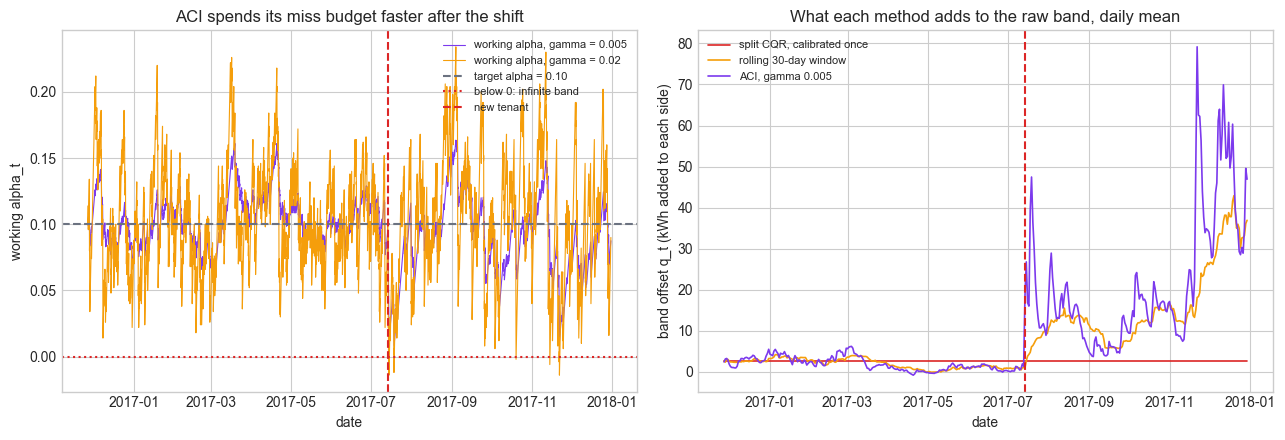

In [9]:
for gamma in (0.005, 0.02):
    a = alpha_paths[gamma][START:]
    print(f"gamma = {gamma}: working alpha {a[~post].min():.3f} to {a[~post].max():.3f} before the "
          f"shift, {a[post].min():.3f} to {a[post].max():.3f} after")
daily_offsets = {name: pd.Series(offsets[name][START:], index=times[START:]).resample("D").mean()
                 for name in ("split CQR, calibrated once", "rolling 30-day window", "ACI, gamma 0.005")}
for name in ("rolling 30-day window", "ACI, gamma 0.005"):
    d = daily_offsets[name]
    two_weeks = d[shift_time:shift_time + pd.Timedelta(days=14)]
    autumn = d["2017-09-01":"2017-11-05"]
    print(f"{name}: daily mean offset peaks at {two_weeks.max():.1f} kWh in the 14 days after the "
          f"shift; {d[shift_time + pd.Timedelta(days=30):].iloc[0]:.1f} kWh 30 days after it; "
          f"{autumn.min():.1f} to {autumn.max():.1f} kWh from 1 September to 5 November; "
          f"stream maximum {d.max():.1f} kWh on {d.idxmax():%Y-%m-%d}")
inf_hours = times[START:][offsets["ACI, gamma 0.02"][START:] == np.inf]
print("infinite-band hours of ACI, gamma 0.02, by day:",
      ", ".join(f"{day:%d %b} {k}" for day, k in pd.Series(1, index=inf_hours).resample("D").sum()
                .loc[lambda c: c > 0].items()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for gamma, color in ((0.005, PURPLE), (0.02, AMBER)):
    ax.plot(times[START:], alpha_paths[gamma][START:], color=color, lw=0.8,
            label=f"working alpha, gamma = {gamma}")
ax.axhline(ALPHA, color=GRAY, ls="--", lw=1.5, label="target alpha = 0.10")
ax.axhline(0, color=RED, ls=":", lw=1.5, label="below 0: infinite band")
ax.axvline(shift_time, color=RED, ls="--", lw=1.5, label="new tenant")
ax.set_title("ACI spends its miss budget faster after the shift")
ax.set_xlabel("date")
ax.set_ylabel("working alpha_t")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
for name, color in (("split CQR, calibrated once", RED), ("rolling 30-day window", AMBER),
                    ("ACI, gamma 0.005", PURPLE)):
    ax.plot(daily_offsets[name].index, daily_offsets[name].to_numpy(), color=color, lw=1.2,
            label=name)
ax.axvline(shift_time, color=RED, ls="--", lw=1.5)
ax.set_title("What each method adds to the raw band, daily mean")
ax.set_xlabel("date")
ax.set_ylabel("band offset q_t (kWh added to each side)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

The left panel is the thermostat at work. Before the shift the working alpha wanders around
0.10, between 0.063 and 0.161 for $\gamma = 0.005$ (purple), and far more nervously for
$\gamma = 0.02$ (amber), between 0.014 and 0.226 before anything had changed. When the tenant
arrives the misses pile up and both settings drop within days: the purple one to its minimum
of 0.008, the amber one through zero to -0.014. The printout dates the amber run's 38
infinite-band hours: 21 fall in the tenant's first five days (14, 15 and 18 July), and the
other 17 come in the October and November dips (19 October, 14, 21 and 22 November). Over the
autumn both settings drift back towards 0.10 as the band catches up, and dip again in
November and December, when heating at the new level pushes the scores higher still.

The right panel shows why ACI beats the rolling window in the weeks after the shift. The
rolling offset (amber) climbs at the speed of its 30-day memory: its daily mean peaks at
9.7 kWh in the first 14 days after the shift and reaches 15.5 kWh after 30. The ACI offset
(purple) peaks at 47.5 kWh within those 14 days, because it responds to misses rather than to
the slowly changing contents of a window, then settles back to 18.7 kWh by day 30. From
September to early November the two move in roughly the same range, 5.7 to 16.5 kWh for the
rolling window and 3.7 to 24.2 kWh for ACI. ACI then spikes to its stream maximum, 79.2 kWh on
22 November, while the rolling window is still climbing towards its own, 42.9 kWh on
20 December. The stale band (red) is the flat line at 2.6 kWh that never moved. Note what the
picture does not show: ACI's offset is still a quantile of the trailing 720 scores, so the
window's content matters to ACI as well; the dial only decides which quantile to read.

## 5. Conformal PID

**Conformal PID** (Angelopoulos, Candes and Tibshirani 2023) borrows the controller every
thermostat engineer knows. Instead of nudging a quantile level and reading a quantile off a
window, it nudges the band offset itself, in kWh. We implement it from scratch, matching the
update logic of the authors' reference code (`core/methods.py` in
github.com/aangelopoulos/conformal-time-series). Three terms:

**P, quantile tracking.** **Quantile tracking** raises the offset after a miss and lowers it
after a hit, with the same 0.9 / 0.1 bookkeeping as ACI, but on the score scale: the knob is
the offset, not a quantile level. In symbols,

$$q_{t+1} = q_t + \eta_t\,(\mathrm{err}_t - \alpha),$$

where $q_t$ is the offset added to the raw CQR band at hour $t$ and the step
$\eta_t = 0.1 \times$ (largest minus smallest of the 300 scores before hour $t$), the reference
code's proportional step: it stretches and shrinks with the recent range of the scores. The
tracker starts at $q_1 = 0$, as in the reference code, which for CQR scores means the raw
quantile band. Note what it does not need: no window to read a quantile from, so no infinite
band from asking a short window for an impossible level. What it can do instead is go
negative. After a run of hits the offset walks below zero and the band shrinks inside the raw
quantile band; if it falls below minus half the raw band's width, the lower edge passes the
upper one and the band is empty. Nothing in the update forbids that: the miss is counted like
any other, and the next update raises the offset.

The guarantee is the same telescoping, on the score scale. The offset cannot wander more than
one step beyond the range of the scores: above the largest score nothing misses, so it falls;
below the smallest, everything misses, so it rises. For scores in $[-b, b]$, a fixed step
$\eta$ and a start at $q_1 = 0$,

$$\left|\frac{1}{T}\sum_{t=1}^{T}(\mathrm{err}_t - \alpha)\right| \;\le\; \frac{b + \eta}{\eta\, T}.$$

Again deterministic, any sequence, long-run only. Our main run uses the proportional step, as
the reference code does, so for it the bound is a guide; we check it as a theorem on a
fixed-step run below.

**I, the integrator.** The tracker reacts to the latest miss. The **integrator** reacts to the
running total of excess misses: if the stream has missed 40 times more than its budget so far,
it adds a cushion that grows with that total, and the tangent makes the cushion explode to
infinity if the total ever becomes absurd. That saturation is what lets the authors prove a
long-run guarantee without assuming the scores are bounded. In symbols,

$$r_t(x) = K_I \tan\left(\frac{x \log t}{C_{\mathrm{sat}}\, t}\right), \qquad x = \sum_{i \le t}(\mathrm{err}_i - \alpha),$$

where $x$ is the running excess of misses after $t$ hours, the tangent is taken as $+\infty$ at
or beyond $\pi/2$ (and $-\infty$ at or below $-\pi/2$), $C_{\mathrm{sat}} = 5$ sets how many
excess misses it takes to saturate (the threshold also grows with $t$, as the printout below
shows), and $K_I$ is the gain. The reference code writes $t + 1$ for
$t$, which avoids a division by zero at the start; we do the same. One indexing difference we
keep on purpose: the reference code's integrator sums the misses before hour $t$, so its I term
reacts one hour later than the formula above; we follow the paper's formula, which includes
the newest miss, and report the reference indexing as a separate row. The authors' configurations
use $K_I = 10$, set for their datasets' score scales; $K_I$ carries the units of the score, so we
scale it to ours: 10 calibration-score ranges, about 1,119 kWh. The factor $\log t / t$ means the
integrator's grip loosens as the stream grows: the same 40 excess misses matter less after a
year than after a week.

**D, the scorecaster.** A **scorecaster** is a forecast of the next score, added on top: if
you can predict that tomorrow at 14:00 will be a hard hour, widen in advance. The authors fit a
time-series model to the scores; we try the cheapest versions, the score 24 hours earlier and
the score 168 hours earlier, and report honestly whether they help.

The offset used for the next hour is the sum of the three,
$q_{t+1} = q^{\mathrm{track}}_{t+1} + r_t(x_t) + \hat s_{t+1}$, where $\hat s_{t+1}$ is the scorecast.

In [10]:
def tan_saturated(x):
    """tan(x) on (-pi/2, pi/2); +inf at or beyond pi/2 and -inf at or below -pi/2."""
    if x >= math.pi / 2:
        return math.inf
    if x <= -math.pi / 2:
        return -math.inf
    return math.tan(x)


def run_conformal_pid(scores, start, alpha, lr=0.1, burn_in=300, K_I=0.0, C_sat=5.0,
                      scorecast=None, fixed_step=None, include_newest=True):
    """Conformal PID control (Angelopoulos, Candes and Tibshirani 2023), from scratch.

    Follows the update logic of the authors' reference code (core/methods.py):
    - P, quantile tracking: q_track += step_t * (err_t - alpha), where
      step_t = lr * (max - min of the `burn_in` scores before t), or `fixed_step` if given.
    - I, integrator: K_I * tan(x * log(n + 1) / (C_sat * (n + 1))), with x the running sum
      of (err_i - alpha) over the n rows streamed so far; tan saturates to +/- infinity.
    - D, scorecaster: an optional forecast of each row's score, added on top.
    The offset for row t is q_track + integrator + scorecast[t]; q_track starts at 0.
    include_newest=True sums the misses up to and including row t (the paper's formula);
    False sums them up to row t - 1, the reference code's indexing (its I term lags an hour).
    """
    q = np.full(len(scores), np.nan)
    q_track, integrator, x, n = 0.0, 0.0, 0.0, 0
    for t in range(start, len(scores)):
        q[t] = q_track + integrator + (scorecast[t] if scorecast is not None else 0.0)
        err_t = float(scores[t] > q[t])               # h = 1: known before row t + 1
        recent = scores[max(t - burn_in, 0):t]
        step_t = fixed_step if fixed_step is not None else lr * (recent.max() - recent.min())
        q_track += step_t * (err_t - alpha)
        x_used, n_used = x, n                         # reference-code indexing: before err_t
        x += err_t - alpha
        n += 1
        if include_newest:
            x_used, n_used = x, n                     # the paper's formula: including err_t
        if K_I > 0:
            integrator = K_I * tan_saturated(x_used * math.log(n_used + 1) / (C_sat * (n_used + 1)))
    return q

K_I = 10 * np.ptp(scores[:START])                     # 10 calibration-score ranges, in kWh
lag_24 = np.r_[np.zeros(24), scores[:-24]]            # scorecast: the score 24 h earlier
lag_168 = np.r_[np.zeros(168), scores[:-168]]         # scorecast: the score 168 h earlier
pid_runs = {
    "P: quantile tracking": run_conformal_pid(scores, START, ALPHA),
    "P + I": run_conformal_pid(scores, START, ALPHA, K_I=K_I),
    "P + I + D (score 24 h earlier)": run_conformal_pid(scores, START, ALPHA, K_I=K_I,
                                                        scorecast=lag_24),
    "P + I + D (score 168 h earlier)": run_conformal_pid(scores, START, ALPHA, K_I=K_I,
                                                         scorecast=lag_168),
    "P, sluggish step (lr 0.01)": run_conformal_pid(scores, START, ALPHA, lr=0.01),
    "P + I, sluggish step (lr 0.01)": run_conformal_pid(scores, START, ALPHA, lr=0.01, K_I=K_I),
    "P + I, reference-code indexing": run_conformal_pid(scores, START, ALPHA, K_I=K_I,
                                                        include_newest=False),
}
for name in ("P: quantile tracking", "P + I", "P + I + D (score 24 h earlier)"):
    offsets[f"PID {name}"] = pid_runs[name]

# The theorem, checked: fixed step, start at 0, b = the largest |score| in the stream.
eta = 0.1 * np.ptp(scores[:START])
q_fixed = run_conformal_pid(scores, START, ALPHA, fixed_step=eta)
b_max = np.max(np.abs(scores[START:]))
gap_fixed = abs(np.mean(scores[START:] > q_fixed[START:]) - ALPHA)
bound_fixed = (b_max + eta) / (eta * T)
assert gap_fixed <= bound_fixed, "the quantile-tracking bound can never fail - check the update"
err_f, q_f = (scores[START:] > q_fixed[START:]).astype(float), q_fixed[START:]
assert abs((q_f[-1] - q_f[0]) - eta * np.sum(err_f[:-1] - ALPHA)) < 1e-8, "updates must telescope"
assert -b_max - ALPHA * eta <= q_f.min() and q_f.max() <= b_max + (1 - ALPHA) * eta, \
    "the offset must stay within one step of the score range"
# Rebuild the I term of the P + I run from its own misses, to see how hard it pushed.
x_path = np.cumsum((scores[START:] > pid_runs["P + I"][START:]) - ALPHA)   # x after n hours
n_path = np.arange(1, T + 1)
arg = x_path * np.log(n_path + 1) / (5.0 * (n_path + 1))
assert np.all(np.abs(arg) < math.pi / 2), "the tangent saturated - the band went infinite"
i_term = K_I * np.tan(arg)                                  # added to the offset of hour n + 1
steps = [0.1 * np.ptp(scores[t - 300:t]) for t in range(START, len(scores))]
print(f"proportional step eta_t: median {np.median(steps):.1f} kWh, "
      f"range {min(steps):.1f} to {max(steps):.1f}")
print(f"K_I = {K_I:.0f} kWh; running excess of misses x between {x_path.min():.1f} "
      f"and {x_path.max():.1f}")
print(f"I term: {i_term[0]:.1f} kWh after the first hour, largest |I| {np.abs(i_term).max():.1f} kWh "
      f"(after hour {np.argmax(np.abs(i_term)) + 1}), "
      f"largest |I| after the shift {np.abs(i_term[post]).max():.1f} kWh")
print(f"theorem check (fixed step eta = {eta:.2f} kWh, b = {b_max:.1f} kWh): "
      f"miss gap {gap_fixed:.4f} <= bound {bound_fixed:.4f}")
for hours_so_far in (1_000, T):
    x_sat = (math.pi / 2) * 5.0 * (hours_so_far + 1) / math.log(hours_so_far + 1)
    share = (x_sat + ALPHA * hours_so_far) / hours_so_far     # miss share that would reach x_sat
    print(f"after {hours_so_far:,} hours the tangent saturates at x = {x_sat:,.0f} excess misses; "
          f"at most {(1 - ALPHA) * hours_so_far:,.0f} are possible, so it would take "
          + (f"{share:.1%} of all hours missed" if share <= 1 else "more misses than hours"))
# Empty bands: an offset below minus half the raw band's width puts the lower edge above the upper.
raw_width = raw_hi[START:] - raw_lo[START:]
print(f"raw quantile band on the stream: median width {np.median(raw_width):.1f} kWh, "
      f"narrowest {raw_width.min():.1f} kWh; the lag-24 scorecast alone dips to "
      f"{lag_24[START:].min():.1f} kWh")
for name in ("P: quantile tracking", "P + I", "P + I + D (score 24 h earlier)"):
    qs = pid_runs[name][START:]
    lo_b, hi_b = raw_lo[START:] - qs, raw_hi[START:] + qs     # the band actually issued
    is_empty = lo_b > hi_b
    print(f"{name}: lowest offset {qs.min():.1f} kWh; {is_empty.sum()} empty bands, "
          f"{np.sum(is_empty & ~post)} of them before the shift; most inverted hi - lo "
          f"{np.min(hi_b - lo_b):.1f} kWh")
report_table({name: building_report(q) for name, q in pid_runs.items()}).round(3)

proportional step eta_t: median 11.3 kWh, range 5.9 to 23.6
K_I = 1119 kWh; running excess of misses x between -1.1 and 15.7
I term: -7.8 kWh after the first hour, largest |I| 65.6 kWh (after hour 2), largest |I| after the shift 3.7 kWh
theorem check (fixed step eta = 11.19 kWh, b = 177.6 kWh): miss gap 0.0005 <= bound 0.0018
after 1,000 hours the tangent saturates at x = 1,138 excess misses; at most 900 are possible, so it would take more misses than hours
after 9,576 hours the tangent saturates at x = 8,205 excess misses; at most 8,618 are possible, so it would take 95.7% of all hours missed
raw quantile band on the stream: median width 28.5 kWh, narrowest 1.3 kWh; the lag-24 scorecast alone dips to -71.1 kWh
P: quantile tracking: lowest offset -15.3 kWh; 5 empty bands, 2 of them before the shift; most inverted hi - lo -5.5 kWh
P + I: lowest offset -19.3 kWh; 11 empty bands, 7 of them before the shift; most inverted hi - lo -8.5 kWh
P + I + D (score 24 h earlier): lowest offset -58.8

,long_run,pre_shift,post_shift,worst_week,weeks_below_0.85,mean_width,interval_score,infinite_bands,empty_bands
P: quantile tracking,0.899,0.900,0.898,0.875,0,74.171,96.849,0,5
P + I,0.899,0.900,0.898,0.875,0,74.954,97.539,0,11
P + I + D (score 24 h earlier),0.899,0.899,0.899,0.887,0,89.535,117.920,0,114
P + I + D (score 168 h earlier),0.899,0.899,0.898,0.869,0,86.534,116.419,0,38
"P, sluggish step (lr 0.01)",0.896,0.899,0.893,0.810,4,68.174,97.032,0,0
"P + I, sluggish step (lr 0.01)",0.897,0.899,0.893,0.827,3,68.692,97.166,0,0
"P + I, reference-code indexing",0.899,0.900,0.898,0.875,0,74.862,97.139,0,8


Seven rows, three findings, one check, and one caution about the last column.

The P term alone does most of the work. Quantile tracking with the reference code's step covers
0.899 over the stream, 0.898 after the shift, with a worst week of 0.875 and no week below
0.85, without a single infinite band. It pays in width: 74.2 kWh on average against 70.5 for
ACI with $\gamma = 0.005$, for an interval score of 96.8 against ACI's 97.7. The median step is
11.3 kWh, so a single miss raises the offset by about 10 kWh at once and nine hits are needed
to walk it back: the band jerks wider after every miss and drifts back slowly. That jerkiness
is the extra width, and it is also why the tracker's weeks stay so close to 90%: it never lets
misses accumulate for long.

The integrator is insurance, and on this stream with this step it barely pays out. The running
excess of misses never leaves the range -1.1 to 15.7, because the tracker keeps correcting it.
In the very first hours the $\log t / t$ factor is large: one hit leaves the I term at
-7.8 kWh, and one miss in the second hour sets it to 65.6 kWh. After the shift, with thousands
of hours behind it, the I term never exceeds 3.7 kWh.
Adding it changes the width by under 1 kWh and coverage not at all. With a sluggish step
(`lr = 0.01`) the integrator earns its keep: the worst week rises from 0.810 to 0.827 for a
width increase of 0.5 kWh. The tangent never came near saturation, and by construction it
rarely can: after 1,000 hours it would take 1,138 excess misses, more than the 900 that are
possible, and after all 9,576 hours it would take 8,205 of a possible 8,618, that is 95.7% of
all hours missed. The saturation is a safety net for streams that go badly wrong, not a
working part of the band. The last row shows that our indexing choice is immaterial here:
with the reference code's one-hour lag the I term is zero after the first hour instead of
-7.8 kWh, and the row reaches the same coverage and worst week (0.899, 0.875) at a width of
74.9 kWh, an interval score of 97.1 and 8 empty bands, against 75.0, 97.5 and 11.

The check: the fixed-step run passes the theorem's bound (miss gap 0.0005 against 0.0018), and
the two facts behind it are asserted exactly, the telescoping identity and the offset staying
within one step of the score range.

The scorecaster did not help, and we will not oversell it. Adding the score from 24 hours
earlier lifts the worst week to 0.887, and pays for it with a much wider band (89.5 kWh against
75.0), the worst interval score of any adaptive method (117.9) and 114 empty bands; the 168-hour
version is similar (86.5 kWh, 116.4, 38 empty bands) without even the worst-week gain. A raw
lagged score is a noisy forecast of the next score, and the noise goes straight into the band,
in both directions: an hour that sat deep inside yesterday's band subtracts up to 71.1 kWh from
today's offset. A scorecaster can help when the scores have structure a forecaster can learn;
ours, residuals of a model that already uses yesterday and last week, have little.

One caution about the `empty_bands` column, the mirror image of ACI's infinite bands. Quantile
tracking lowers the offset by a tenth of a step after every hit, and nothing stops it at zero:
the tracker's lowest offset is -15.3 kWh, more than half the raw quantile band's median width
of 28.5 kWh (the narrowest raw band is 1.3 kWh). Wherever the offset falls below minus half the
raw band's width, the lower edge lands above the upper edge and the band is empty. The tracker
alone produced 5 such hours, 2 of them before the shift; with the integrator, 11 (7 before);
with the lag-24 scorecaster, whose offset fell to -58.8 kWh, 114 (93 before). The sluggish step
produced none. Operationally, an empty band means the system shows no range at all for that
hour: a guaranteed miss, and, if its edges were alarm limits (notebook 14), an alarm on every
reading, since any value lies above the upper edge or below the lower one. It is not notebook
04's honest empty set, which says that no label passed the bar; it says that the controller
overshot, after a run of hits for the tracker, or after an hour yesterday that sat deep inside
its band for the scorecaster. The coverage columns count every empty band as a miss, as the
long-run guarantee does. The width and interval-score columns leave them out, like infinite
bands: kept in, the most inverted band of the scorecaster run would have entered the width
average at -79.5 kWh, a negative width that flatters the method that produced it.

## 6. Bake-off

One table, every method on the same 9,576 hours. The columns: long-run coverage over the 57
weeks; coverage before and after the shift; the worst week and the number of weeks below 0.85;
mean width and interval score over the finite, non-empty bands (lower is better for both, field
guide §18); the numbers of infinite and empty bands, whose hours are left out of those two
averages; and the interval score again under two other conventions for those hours, so that you
can see whether leaving them out decides anything.
Read the worst-week column before the long-run column.

In [11]:
bakeoff = report_table({name: building_report(q) for name, q in offsets.items()})

# Does leaving infinite and empty bands out decide the price ranking? Two other conventions.
bands = {name: (raw_lo[START:] - q[START:], raw_hi[START:] + q[START:]) for name, q in offsets.items()}
common = np.logical_and.reduce([np.isfinite(lo) & np.isfinite(hi) & (lo <= hi)
                                for lo, hi in bands.values()])
for name, (lo, hi) in bands.items():
    # (1) Only the hours on which EVERY method in the table issued a finite, non-empty band.
    bakeoff.loc[name, "IS_common_hours"] = interval_score(y[START:][common], lo[common],
                                                          hi[common], ALPHA)
    # (2) Every finite hour, an empty band scored as a zero-width band at its crossing midpoint.
    fin = np.isfinite(lo) & np.isfinite(hi)
    lo_f, hi_f = lo[fin], hi[fin]
    mid, empty = (lo_f + hi_f) / 2, lo_f > hi_f
    bakeoff.loc[name, "IS_empty_as_point"] = interval_score(
        y[START:][fin], np.where(empty, mid, lo_f), np.where(empty, mid, hi_f), ALPHA)
print(f"hours on which every method issued a finite, non-empty band: {common.sum():,} of {len(common):,}")
bakeoff.round(3)

hours on which every method issued a finite, non-empty band: 9,410 of 9,576


,long_run,pre_shift,post_shift,worst_week,weeks_below_0.85,mean_width,interval_score,infinite_bands,empty_bands,IS_common_hours,IS_empty_as_point
"split CQR, calibrated once",0.843,0.915,0.745,0.548,21,55.071,107.910,0,0,105.973,107.910
rolling 30-day window,0.891,0.902,0.876,0.702,6,65.472,98.896,0,0,97.015,98.896
"recency-weighted, rho 0.9",0.897,0.904,0.887,0.768,4,67.378,98.721,0,0,96.941,98.721
"recency-weighted, rho 0.97",0.887,0.906,0.861,0.702,7,63.346,99.208,0,0,97.326,99.208
"ACI, gamma 0.005",0.900,0.900,0.900,0.815,4,70.492,97.694,0,0,96.543,97.694
"ACI, gamma 0.02",0.900,0.900,0.900,0.863,0,69.491,93.926,38,0,94.650,93.926
PID P: quantile tracking,0.899,0.900,0.898,0.875,0,74.171,96.849,0,5,96.240,96.920
PID P + I,0.899,0.900,0.898,0.875,0,74.954,97.539,0,11,96.958,97.622
PID P + I + D (score 24 h earlier),0.899,0.899,0.899,0.887,0,89.535,117.920,0,114,116.771,118.327


Read the table in the order the facilities lead would: worst week first, long run second,
price third.

**Worst week.** The stale band's worst week is 0.548 and 21 of its 57 weeks sit below 0.85. The
recalibration family lifts the worst week to between 0.702 and 0.768; ACI to 0.815 with
$\gamma = 0.005$, or 0.863 with $\gamma = 0.02$ at the cost of 38 infinite hours; conformal PID
to 0.875 with the tracker alone, and to 0.887 with the lag-24 scorecaster, which also left 114
hours with no band at all. Only ACI with $\gamma = 0.02$ and the three PID rows have no week
below 0.85.

**Long run.** Every row except the stale band lands between 0.887 and 0.900. ACI and PID land at
0.899 or 0.900, well inside ACI's bounds over 9,576 hours. The recalibration rows fall a little
short, which their bound allows: 90% minus a weighted distance that a shift makes large.

**Price.** The stale band is the narrowest (55.1 kWh) because it never widened for the new
tenant, and its interval score (107.9) is the worst in the table after the lag-24 scorecaster's: the interval score charges
every miss 2 / 0.10 = 20 times its distance outside the band, and after the shift the misses
are many and far. Among the adaptive methods without a scorecaster, widths run from 63.3 to
75.0 kWh and interval scores from 93.9 to 99.2. PID buys its steadier weeks with 4.5 kWh
more width than ACI with $\gamma = 0.005$, at an essentially equal interval score (97.5 against
97.7). ACI with $\gamma = 0.02$ shows the lowest interval score, 93.9, but it is averaged over
the finite hours only; its 38 infinite hours are not in it. The PID rows have the opposite
exclusion: their 5, 11 and 114 empty hours are not in the width or the interval score either,
and appear only as misses in the coverage columns. Neither exclusion decides the ranking
beyond near-ties. `IS_common_hours` scores every method on the same 9,410 of the 9,576 hours, those on which all
nine issued a finite, non-empty band; `IS_empty_as_point` keeps every finite hour and scores an
empty band as a zero-width band at its crossing midpoint. Under the second convention every row
keeps its place. Under the first, PID P + I slips two places, both among methods the text already treats as
tied: behind ACI with $\gamma = 0.005$ (96.5 against 97.0) and, by 0.02, behind the
recency-weighted band with $\rho = 0.9$ (96.94 against 96.96). ACI with $\gamma = 0.02$ stays
the lowest (94.7 on the common hours), and the stale band and the lag-24 scorecaster stay the
two worst (106.0 and 116.8).

What the table does not say: it is one stream, one shift, one seed, and we have not checked
how differences of a few interval-score points between the adaptive methods move across seeds,
so treat them as a tie. The robust message is the ordering on the worst week: calibrated once,
then recalibrated daily, then corrected after every miss. And none of the knobs ($\rho$,
$\gamma$, the PID step) was tuned on this stream; tuning them here and quoting the result would
be calibrating on the test period (field guide §15).

split CQR, calibrated once  shift week and the four after: 0.756 0.720 0.863 0.762 0.768   worst week 0.548 (2017-11-19)
rolling 30-day window       shift week and the four after: 0.732 0.774 0.911 0.863 0.911   worst week 0.702 (2017-11-19)
recency-weighted, rho 0.9   shift week and the four after: 0.786 0.887 0.940 0.869 0.875   worst week 0.768 (2017-11-19)
ACI, gamma 0.005            shift week and the four after: 0.815 0.929 0.958 0.881 0.917   worst week 0.815 (2017-07-09)
PID P + I                   shift week and the four after: 0.875 0.917 0.899 0.887 0.899   worst week 0.875 (2017-07-09)


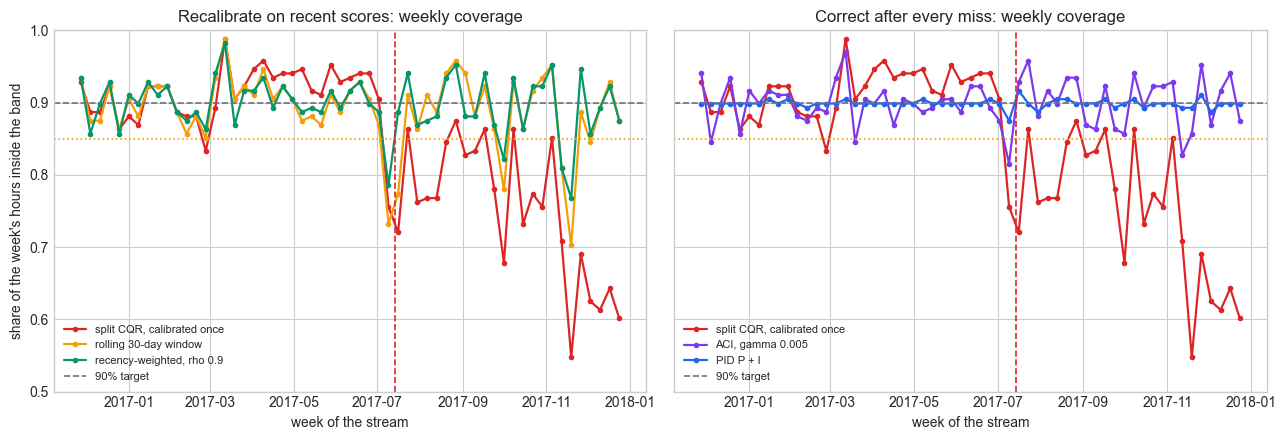

In [12]:
families = [
    ("Recalibrate on recent scores", [("split CQR, calibrated once", RED),
                                      ("rolling 30-day window", AMBER),
                                      ("recency-weighted, rho 0.9", GREEN)]),
    ("Correct after every miss", [("split CQR, calibrated once", RED),
                                  ("ACI, gamma 0.005", PURPLE),
                                  ("PID P + I", BLUE)]),
]
for name in ("split CQR, calibrated once", "rolling 30-day window", "recency-weighted, rho 0.9",
             "ACI, gamma 0.005", "PID P + I"):
    wk = block_coverage(offsets[name], scores, START, WEEK)
    print(f"{name:<27} shift week and the four after: "
          f"{' '.join(f'{c:.3f}' for c in wk[first_post_week:first_post_week + 5])}   "
          f"worst week {wk.min():.3f} ({week_start[np.argmin(wk)]:%Y-%m-%d})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (title, members) in zip(axes, families):
    for name, color in members:
        ax.plot(week_start, block_coverage(offsets[name], scores, START, WEEK), color=color,
                lw=1.6, marker="o", ms=3, label=name)
    ax.axhline(1 - ALPHA, color=GRAY, ls="--", lw=1.2, label="90% target")
    ax.axhline(0.85, color=AMBER, ls=":", lw=1.2)
    ax.axvline(shift_time, color=RED, ls="--", lw=1.2)
    ax.set_title(f"{title}: weekly coverage")
    ax.set_xlabel("week of the stream")
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("share of the week's hours inside the band")
axes[0].set_ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

The left panel is the recalibration family. Until July the rolling window (amber) and the
recency-weighted band (green) follow the stale band's (red) ups and downs a few points lower,
most visibly in spring: recalibration also trims the stale band's pre-shift over-coverage
(0.902 and 0.904 before the shift, against 0.915). In the week of the shift all
three fall together (0.756 stale, 0.732 rolling, 0.786 weighted), because all three are still
calibrated on the old building; by the second week after it the two recalibrated bands cover
0.911 and 0.940, while the stale band touches 0.863 that week and falls back. Both recalibrated
bands dip again in November, when the heating season moves the scores a second time, which is
where their worst weeks sit.

The right panel is the online family, and it shows something the tables cannot. ACI (purple)
drops to its worst week, 0.815, in the week of the shift, and then covers 0.929 and 0.958 in
the two weeks after it: it is paying back the misses. That is the long-run guarantee working
exactly as designed, because a bad week is compensated by over-covered weeks until the average
returns to 0.90. It is also why a long-run guarantee is not the promise the facilities lead
asked for: the over-covered weeks are wider bands that nobody needed, bought to repair an
average. PID (blue) hugs 0.90 almost every week; its worst week, 0.875, is the week of the
shift, and the four after it cover between 0.887 and 0.917. Its large proportional step
corrects within days, before misses can pile up into a bad week, and pays with the extra width
seen in the bake-off.

The numbers to quote from this figure are the printed ones: the week of the shift and the four
after it, for each method. The pattern to remember is the shape: recalibration lags, ACI dips
and overshoots, PID wobbles narrowly around the target at a higher width.

### The same comparison on a VM

The building's shift was one step on a slow, regular series. A VM is bursty, and its level
jumps when the service is redeployed (the `simulate_vm_cpu` docstring). One caution before we
reuse the main VM series: with `RANDOM_SEED`, both of the simulator's own redeploys happen
within the first 12 days, inside the 14 days that the same-time features of
`make_direct_table` consume, so the usable stream contains no level shift at all. Rather than
pretend otherwise, we redeploy the service ourselves, on a copy of the series: from day 24 on,
every reading is multiplied by 1.4 and clipped at 100. A factor of 1.4 is about one standard
deviation of the simulator's own redeploy jumps (lognormal, sigma 0.35). The protocol follows
the VM conventions of notebooks 11 and 12, scaled down: `h = 1` (five minutes ahead), the three
quantile models fitted once on days 14-18, one day (288 readings) of calibration, then ten days
streamed, four before the redeploy and six after. The rolling window and ACI use the same
one-day window, and "worst day" replaces "worst week".

In [13]:
VM_SHIFT_DAY, DAY5 = 24, 288
v = simulate_vm_cpu(30, seed=RANDOM_SEED)
step = np.arange(len(v))
cpu = pd.Series(np.clip(v["cpu_pct"].to_numpy() * np.where(step >= DAY5 * VM_SHIFT_DAY, 1.4, 1.0),
                        0.0, 100.0), index=v.index)
vtab = make_direct_table(cpu, h=1, period=DAY5)
v_step = ((vtab["target_time"] - v.index[0]) / pd.Timedelta(minutes=5)).to_numpy().astype(int)
v_train, v_cal = v_step < DAY5 * 19, (v_step >= DAY5 * 19) & (v_step < DAY5 * 20)
v_keep = v_cal | (v_step >= DAY5 * 20)

VX, vy_all = vtab[MODEL_FEATURES].to_numpy(), vtab["target"].to_numpy()
v_models = {q: quantile_gbm(q).fit(VX[v_train], vy_all[v_train])
            for q in (ALPHA / 2, 0.5, 1 - ALPHA / 2)}
v_lo = v_models[ALPHA / 2].predict(VX[v_keep])
v_point = v_models[0.5].predict(VX[v_keep])
v_hi = v_models[1 - ALPHA / 2].predict(VX[v_keep])
vy = vy_all[v_keep]
v_scores = np.maximum(v_lo - vy, vy - v_hi)          # the same CQR score as the building
V_START = int(v_cal.sum())
v_post = v_step[v_keep][V_START:] >= DAY5 * VM_SHIFT_DAY


def vm_report(q):
    """stream_report on the VM stream, reported per day instead of per week."""
    return stream_report(q, v_scores, v_lo, v_hi, vy, V_START, v_post, DAY5, block_name="day")


v_roll = np.full(len(v_scores), np.nan)
for t in range(V_START, len(v_scores), DAY5):
    v_roll[t:t + DAY5] = corrected_quantile(v_scores[t - DAY5:t], ALPHA)
v_K_I = 10 * np.ptp(v_scores[:V_START])
vm_offsets = {
    "split CQR, calibrated once": np.full(len(v_scores),
                                          corrected_quantile(v_scores[:V_START], ALPHA)),
    "rolling 1-day window": v_roll,
    "ACI, gamma 0.005": run_aci(v_scores, V_START, ALPHA, 0.005, DAY5)[0],
    "ACI, gamma 0.02": run_aci(v_scores, V_START, ALPHA, 0.02, DAY5)[0],
    "PID P: quantile tracking": run_conformal_pid(v_scores, V_START, ALPHA),
    "PID P + I": run_conformal_pid(v_scores, V_START, ALPHA, K_I=v_K_I),
}
print("daily mean % CPU of the raw simulation, days 0-13 (its own redeploys):",
      np.round(v["cpu_pct"].resample("D").mean().to_numpy()[:14], 1))
v_miss = (v_scores[V_START:] > vm_offsets["ACI, gamma 0.005"][V_START:]).astype(float)
b_miss = (scores[START:] > offsets["ACI, gamma 0.005"][START:]).astype(float)
print(f"lag-1 correlation of consecutive ACI (gamma 0.005) misses: "
      f"VM {np.corrcoef(v_miss[:-1], v_miss[1:])[0, 1]:.3f}, "
      f"building {np.corrcoef(b_miss[:-1], b_miss[1:])[0, 1]:.3f}")
print(f"VM: {v_train.sum()} training readings, {V_START} calibration, {len(v_scores) - V_START} "
      f"streamed ({np.sum(~v_post)} before the redeploy, {np.sum(v_post)} after)")
print(f"MAE of the median model: before {np.mean(np.abs(vy - v_point)[V_START:][~v_post]):.2f}, "
      f"after {np.mean(np.abs(vy - v_point)[V_START:][v_post]):.2f} % CPU")
for name in ("PID P: quantile tracking", "PID P + I"):
    qs = vm_offsets[name][V_START:]
    is_empty = (v_lo[V_START:] - qs) > (v_hi[V_START:] + qs)
    print(f"{name}: lowest offset {qs.min():.2f} % CPU; {is_empty.sum()} empty bands, "
          f"{np.sum(is_empty & ~v_post)} of them before the redeploy")
report_table({name: vm_report(q) for name, q in vm_offsets.items()}).round(3)

daily mean % CPU of the raw simulation, days 0-13 (its own redeploys): [27.5 30.6 35.7 36.2 48.5 46.2 43.3 46.9 45.1 47.3 44.9 50.  52.8 54. ]
lag-1 correlation of consecutive ACI (gamma 0.005) misses: VM 0.026, building 0.219
VM: 1440 training readings, 288 calibration, 2880 streamed (1152 before the redeploy, 1728 after)
MAE of the median model: before 2.72, after 4.55 % CPU
PID P: quantile tracking: lowest offset -4.82 % CPU; 2 empty bands, 2 of them before the redeploy
PID P + I: lowest offset -4.87 % CPU; 4 empty bands, 4 of them before the redeploy


,long_run,pre_shift,post_shift,worst_day,days_below_0.85,mean_width,interval_score,infinite_bands,empty_bands
"split CQR, calibrated once",0.739,0.901,0.631,0.559,6,14.720,34.563,0,0
rolling 1-day window,0.876,0.907,0.856,0.556,1,19.370,30.149,0,0
"ACI, gamma 0.005",0.901,0.899,0.902,0.878,0,20.217,28.846,0,0
"ACI, gamma 0.02",0.900,0.900,0.900,0.892,0,20.391,29.119,0,0
PID P: quantile tracking,0.899,0.898,0.900,0.892,0,22.034,30.789,0,2
PID P + I,0.899,0.899,0.899,0.892,0,22.791,31.458,0,4


The first printed line confirms the caution: the raw series steps up between days 3 and 4
(36.2 to 48.5 % CPU) and again around days 10 to 12 (44.9 to 52.8), all before the table's
first row on day 14. The staged redeploy on day 24 is the only shift the stream contains.

The VM repeats the building's story in a faster, noisier register. Before the redeploy every
method covers between 0.898 and 0.907. After it, the stale band falls to 0.631, with a worst day
of 0.559 and six of the ten streamed days below 0.85, while the median model's error rises from
2.72 to 4.55 % CPU. The rolling one-day window recovers on average (0.856 after the redeploy),
but its worst day, 0.556, is no better than the stale band's: it recomputes once a day from the
previous day's scores, so on the day of the redeploy it is calibrated entirely on the old
service. ACI and PID hold the long run between 0.899 and 0.901 and lift the worst day to between
0.878 and 0.892. Those worst days are about as good as a calibrated band can look here. The
VM's misses barely travel together: consecutive ACI misses have a lag-1 correlation of 0.026 on
the VM against 0.219 on the building, the contrast notebook 10 found. With nearly independent
misses, the share covered in a day of 288 readings scatters around 0.90 with a standard
deviation of about 0.018 (the square root of 0.9 x 0.1 / 288), so a worst day of 0.88 out of ten
is ordinary noise, not drift.

The price ranking is not the building's. On the VM, ACI with $\gamma = 0.005$ has the lowest
interval score (28.8) and PID the widest bands (22.0 and 22.8 % CPU against 20.2 for ACI); the
stale band is again the narrowest (14.7) and has the worst interval score (34.6). PID is also
the only method that left readings with no band at all: 2 for the tracker and 4 with the
integrator, out of 2,880, every one of them before the redeploy. In the calm days a run of hits
walks the offset below zero (its lowest values are -4.82 and -4.87 % CPU), and a narrow raw
band does the rest. The message transfers, the winner does not: which online method is cheapest depends on the series, and with
one VM and one staged redeploy we would not crown one. What does transfer is the column you
read first: the worst day, not the long run.

## 7. Two practical details

**Delayed feedback.** Everything above used `h = 1`: the miss of the band for 14:00 is known at
14:00, before the band for 15:00 is issued. For a day-ahead band (`h = 24`), the band for 14:00
tomorrow is issued at 14:00 today, and the newest miss you know at that moment is the one for
14:00 today, from a band issued 24 hours ago. So every update must use the newest error that
has actually arrived, $\mathrm{err}_{t-h}$ in forecast-origin terms, never one whose target is
still in the future; in the reference code that is the index `t_pred = t - ahead + 1`. Updating
with an error you could not yet have observed is notebook 11's leak in a new costume (field
guide §15). The cost of honest delay is reaction time: for the first `h` steps after a shift
the method is flying blind, and the long-run bounds pick up an extra term proportional to `h`,
because the offset can overshoot by up to `h` steps before its feedback arrives. Calibrate each
horizon separately, with its own update stream (field guide §19).

**Cold start.** A new building or VM has no calibration history. Three options, often combined.
First, a burn-in: run the online method from the first hour but quote nothing until it has seen a
few hundred hours; the reference code's `T_burnin` exists for exactly this. Second, borrowed
calibration: start from scale-free scores of similar sites. Notebook 09 §3 showed that a new
building calibrated on its peers is covered on average across buildings and is a lottery for
any single one (field guide §13), which is a reasonable place to start an online method, not to
stop. Third, wide initial bands: start ACI at a small $\alpha_1$, or quantile tracking at a large
offset, and let the method narrow. The long-run bounds do not care where you start; the
starting point enters only through the constant on top of the fraction, so starting wide costs
width early and never the guarantee.

## 8. What each guarantee actually says

| Method | What is guaranteed | Under what assumption | What it does NOT say | Where |
|---|---|---|---|---|
| Split CQR, calibrated once | coverage of at least 90%, finite-sample, on average over calibration draws and the test hour | calibration and future hours exchangeable | nothing once the world drifts: our stream fell from 0.915 to 0.745 | notebooks 05, 12; section 2 |
| Rolling-window recalibration | the recency-weighted bound of the next row, with weight 1 inside the window and 0 outside: at least 90% minus the average total-variation gap over the window's hours | the window is fixed by age, in advance; the gap is small only if the window's hours resemble today | the size of the gap, which is never observed; how long it lags after a shift (here weeks) | section 3 |
| Recency-weighted conformal (Barber et al. 2023) | coverage of at least 90% minus a weighted total-variation gap; the full 90% if the data are exchangeable | weights fixed in advance; the gap is small only if heavily weighted hours resemble today | the size of the gap, which is never observed | section 3 |
| ACI (Gibbs and Candes 2021) | long-run miss rate within (max(alpha_1, 1 - alpha_1) + gamma) / (gamma T) of alpha | none: any sequence, deterministic | anything about a given week, hour or building; it can return infinite (and empty) bands | section 4 |
| Conformal PID, quantile tracking (Angelopoulos et al. 2023) | long-run miss rate within (b + eta) / (eta T) of alpha for scores in [-b, b] and a fixed step; the saturated integrator extends a long-run guarantee to unbounded scores | none beyond bounded scores (or the saturation): any sequence | anything about a given week; with a proportional step the bound is a guide, not a theorem; it can return empty bands when the offset falls below minus half the raw band's width (up to 114 hours here) | section 5 |
| EnbPI, SPCI (Xu and Xie 2021, 2023) | asymptotic coverage | a stationary, mixing series and a consistent model | anything in finite samples or across a regime change | bonus 02 |
| Any distribution-free method | no method can guarantee coverage at a given hour, building or machine without trivial (infinite) bands (Foygel Barber and colleagues 2021) | - | - | notebook 03 §6 |

The last row is the ceiling on all the others. Coverage "for this building, this week" is not a
missing feature that a cleverer method will add; it is impossible without assumptions. What the
online methods add is a guarantee that needs no exchangeability at all, and it is a statement
about long averages. A project report should say which row it is quoting.

## 9. Common mistakes to avoid

1. **Quoting long-run coverage alone.** ACI with $\gamma = 0.001$ covered 0.898 over 57 weeks and
   0.738 in its worst week; split CQR's 0.843 hid a week at 0.548. Report the worst week and the
   number of weeks below a threshold next to every long-run figure (field guide §22).
2. **Calibrating once and calling it monitored.** The stale band fell from 0.915 to 0.745 and
   nothing raised an error. Watch rolling coverage or run notebook 09's conformal test
   martingale, and switch to online calibration when it fires (field guide §6, §10, §14).
3. **Averaging width over finite, non-empty bands without saying so.** ACI with $\gamma = 0.05$
   showed the lowest interval score of its sweep (90.2) by excluding its 214 infinite hours.
   Count infinite bands in their own column, and treat each one as an honest "cannot certify
   this hour" to be routed to a fallback rule or a person, not capped in silence (field guide
   §7). Empty bands need the same column: left in the average, PID's lag-24 run would have added
   widths as negative as -79.5 kWh. Do not repair them by swapping the edges or clipping the
   offset; that is a different rule from the one whose guarantee you checked. And check that a
   ranking survives on the hours where every method issued a finite, non-empty band.
4. **Tuning $\gamma$, $\rho$ or the PID step on the stream you report.** Choose them on an
   earlier period with the walk-forward protocol (field guide §15), or aggregate several step
   sizes as AgACI does; then report the stream you did not tune on.
5. **Adding every term because the paper has it.** Our lag-24 scorecaster widened the PID band
   from 75.0 to 89.5 kWh, raised the interval score from 97.5 to 117.9 and left 114 hours with
   no band at all. Add the integrator and the scorecaster one at a time and keep each only if the interval score says so (field
   guide §18).
6. **Updating with feedback you would not yet have.** For an `h`-step band, the newest miss you
   know is the one whose target has arrived, `h` steps after its forecast was issued. Updating
   with anything newer leaks the future into the band (field guide §15, §19).
7. **Expecting the band layer to fix the model.** After the shift the median model's error more
   than doubled (MAE 10.33 to 23.34 kWh). Online calibration buys coverage with width; only a
   refit buys back accuracy and narrow bands (field guide §5).

## 10. What to say in the project report

**Strong version**

> We compared four band layers on a simulated two-year hourly meter whose load rises 25% in
> mid-July of the second year, with the forecasting model fitted once. Split CQR calibrated once
> covered 91.5% of hours before the shift and 74.5% after, with a worst week of 54.8%. Online
> calibration restored the long-run rate: over 9,576 streamed hours ACI (gamma = 0.005) covered
> 90.0% and conformal PID (quantile tracking plus integrator) 89.9%, with worst weeks of 81.5% and
> 87.5%, at mean widths of 70.5 and 75.0 kWh against 55.1 kWh for the stale band, and interval
> scores of 97.7 and 97.5 against 107.9. These are long-run guarantees for any sequence and say
> nothing about a given week; larger ACI steps produced up to 214 infinite-band hours, and
> conformal PID 11 empty-band hours (no range issued, a guaranteed miss), which we report
> separately and leave out of the width and interval-score averages. The band layer cannot
> repair the model, whose error more than doubled after the shift (MAE 10.3 to 23.3 kWh), so we also recommend a scheduled refit. A staged redeploy on a
> simulated VM gave the same qualitative picture.

**Weak version**

> We switched to ACI, which guarantees 90% coverage under any distribution shift, so the bands
> are valid again every week.

The weak version takes a statement about the long-run average, which is true for any sequence,
and turns it into a weekly promise, which no method in this notebook keeps: ACI's own worst week
was 0.815, and it reached 0.90 overall partly by over-covering the weeks that followed. It also
omits the price, in width and in infinite or empty bands. The strong version quotes the worst
week next to the long run, names which guarantee it relies on (the ACI row of section 8's table), and says
what the band layer cannot do.

### The one-line summary

Split conformal kept its promise for the building it was calibrated in and broke it, silently,
for the building that replaced it. Recalibrating on recent scores repairs most of the damage
with a lag; ACI and conformal PID turn the stream of hits and misses into a feedback signal and
come with a guarantee that needs no exchangeability at all: the long-run miss rate converges to
the budget, for any sequence, deterministically. That guarantee is real and it is narrow. It is
about the whole stream, it is paid for in width and sometimes in infinite or empty bands, and
it says nothing about the week the facilities lead will ask about. Report the worst week next to the
long run, and refit the model you are wrapping.

Online calibration keeps its promise over the year, and the year is made of weeks you will be asked about.